# Pre-entrega 2 · Diagnóstico del corpus AG News
**Hans Dresda | Data Science III**

¿Conserva el texto señales temáticas después de la limpieza y qué longitud representa al 95 % de las noticias? El análisis usa exclusivamente entrenamiento. Se conserva el texto original para comparar TF-IDF y Transformers en los siguientes módulos.

**Ejecución.** Descomprime el proyecto y abre este notebook desde la raíz o desde `notebooks/`. Instala `requirements.txt` en el entorno del kernel; incluye el modelo `en_core_web_sm`. Ejecuta las celdas en orden.

In [1]:
import html
import math
import re
import sys
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import spacy
from IPython.display import display
from sklearn.feature_extraction.text import CountVectorizer

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'data' / 'cargar_dataset.py').is_file())
sys.path.insert(0, str(ROOT / 'data'))
from cargar_dataset import cargar

OUT = ROOT / 'reports' / 'nlp'
OUT.mkdir(parents=True, exist_ok=True)
train, test = cargar('ag_news')
assert list(train.columns) == list(test.columns) == ['text', 'label']
print(f'Entrenamiento: {len(train):,} | Prueba reservada: {len(test):,}')
del test
assert train.notna().all().all() and train.text.str.strip().ne('').all()
assert set(train.label) == {'World', 'Sports', 'Business', 'Sci_Tech'}
print('Filas duplicadas en train:', train.duplicated().sum())
display(train.head(3))

Entrenamiento: 8,000 | Prueba reservada: 2,000
Filas duplicadas en train: 0


,text,label
0,"Red Hat Appoints New CFO. September 2, 2004 --...",Sci_Tech
1,"Sprint, SBC In Hotspot Roaming Deal. Sprint an...",Sci_Tech
2,Radio Outage Grounds West Coast Flights. Airpo...,Business


## 1 · Limpieza y lematización
Se reparan entidades numéricas sin ampersand antes de decodificar HTML. Se eliminan etiquetas, URL, números aislados y signos. El modelo inglés recibe el texto con sus mayúsculas para apoyar el etiquetado gramatical. La salida se normaliza a minúsculas después de obtener el lema. Se unifican variantes de EE. UU. en `usa` para distinguir el país del pronombre inglés *us*. Se conservan las negaciones *no*, *not* y *never*.

Los tokens se usan para un EDA léxico. El filtrado puede quitar cifras económicas, marcadores deportivos y palabras funcionales. Para el modelo contextual se conserva la noticia original.

In [2]:
nlp = spacy.load('en_core_web_sm', disable=['ner', 'parser'])
keep = {'no', 'not', 'never'}
stops = nlp.Defaults.stop_words

def clean_text(text):
    text = unicodedata.normalize('NFKC', text)
    text = re.sub(r'(?<!&)#(\d{2,5});', r'&#\1;', text)
    text = html.unescape(html.unescape(text))
    text = re.sub(r'</?[A-Za-z][^<>]*>', ' ', text)
    # Firmas de agencia en encabezados y enlaces bursátiles de la fuente.
    text = re.sub(r'\((AP|AFP|Reuters|Canadian Press)\)\.?\s*\1\s*[-–—]', ' ', text, flags=re.I)
    text = re.sub(r'\((?:AP|AFP|Reuters|CP|Canadian Press)\)\s*[-–—]?', ' ', text, flags=re.I)
    text = re.sub(r'\([^()]{0,35}:\s*Quote,\s*Profile,\s*Research\)', ' ', text, flags=re.I)
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text, flags=re.I)
    text = re.sub(r'\b(?:U\.S\.(?:A\.)?|US|USA)(?!\w)', 'USA', text)
    text = re.sub(r"\s+['’]s\b", "'s", text)
    return ' '.join(text.split())

def word_tokens(doc, filter_stops=True):
    words = []
    for token in doc:
        lemma = token.lemma_.casefold()
        if not lemma.isalpha() or len(lemma) < 2:
            continue
        if filter_stops and lemma not in keep and (token.is_stop or lemma in stops):
            continue
        words.append(lemma)
    return words

def preprocess_text(text):
    return ' '.join(word_tokens(nlp(clean_text(text))))

example = train.loc[train.text.str.contains('&lt;', regex=False), 'text'].iloc[0]
print('Original:', example)
print('Procesado:', preprocess_text(example))

Original: Verizon, Qwest Ask Court to Block Rules. Verizon and Qwest asked a federal court to block temporary rules forcing the companies to lease phone lines to rivals for at least another six months. &lt;FONT face="verdana,MS Sans Serif,arial,helvetica" size="-2" color="#666666"&gt;&lt;B&gt;-Reuters&lt;/B&gt;&lt;/FONT&gt;
Procesado: verizon qwest ask court block rule verizon qwest ask federal court block temporary rule force company lease phone line rival month


## 2 · Corpus de entrenamiento
La ejecución por lotes usa exactamente las funciones de limpieza y selección del ejemplo. Se comprueba su equivalencia en una muestra y se conserva la correspondencia con la fila original.

In [3]:
from collections import Counter

before_stop = Counter()
texts = []
docs = nlp.pipe((clean_text(text) for text in train.text), batch_size=128)
for doc in docs:
    before_stop.update(word_tokens(doc, filter_stops=False))
    texts.append(' '.join(word_tokens(doc)))

corpus = train.copy()
corpus['text_clean'] = texts
corpus['n_tokens'] = corpus.text_clean.str.split().str.len()
assert corpus.text_clean.head(3).tolist() == [preprocess_text(t) for t in train.text.head(3)]
assert corpus.n_tokens.min() > 0
corpus.to_csv(OUT / 'ag_news_train_preprocesado.csv', index=False)
display(corpus[['label', 'text_clean', 'n_tokens']].head(3))

,label,text_clean,n_tokens
0,Sci_Tech,red hat appoints new cfo september web host in...,19
1,Sci_Tech,sprint sbc hotspot roaming deal sprint sbc com...,19
2,Business,radio outage grounds west coast flights airpor...,22


## 3 · Longitud y balance
La longitud cuenta lemas conservados por noticia. Para el parámetro entero `max_len` se redondea el P95 hacia arriba. La cobertura incluye empates en el umbral. Para un Transformer habrá que medir nuevamente con su tokenizador de subpalabras y sus tokens especiales.

Mediana: 22 | P95: 31 | max_len: 31
Documentos sobre el umbral: 370 de 8000


,documentos,porcentaje
label,,
Business,2000,25.0
Sci_Tech,2000,25.0
Sports,2000,25.0
World,2000,25.0


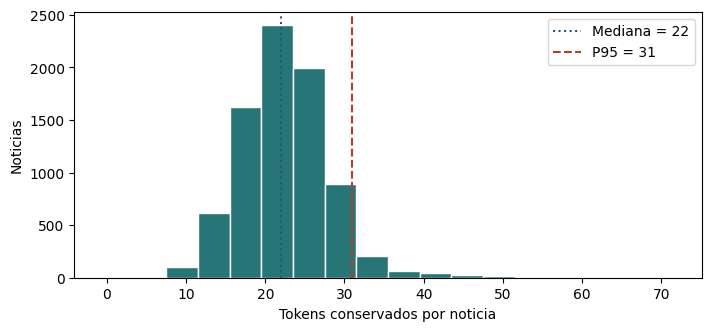

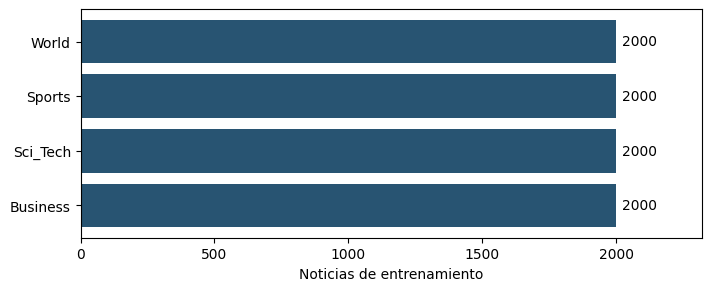

In [4]:
length = corpus.n_tokens
p95 = length.quantile(0.95)
max_len = math.ceil(p95)
counts = corpus.label.value_counts().sort_index()
print(f'Mediana: {length.median():g} | P95: {p95:g} | max_len: {max_len}')
print(f'Documentos sobre el umbral: {(length > max_len).sum()} de {len(length)}')
display(counts.rename('documentos').to_frame().assign(porcentaje=counts * 100 / len(corpus)))

def draw_length():
    fig, ax = plt.subplots(figsize=(7, 3.2), layout='constrained')
    ax.hist(length, bins=np.arange(-0.5, length.max() + 5, 4), color='#287577', edgecolor='white')
    ax.axvline(length.median(), color='#285472', linestyle=':', label=f'Mediana = {length.median():g}')
    ax.axvline(max_len, color='#b63e22', linestyle='--', label=f'P95 = {p95:g}')
    ax.set(xlabel='Tokens conservados por noticia', ylabel='Noticias')
    ax.legend()
    return fig

def draw_classes():
    fig, ax = plt.subplots(figsize=(7, 2.8), layout='constrained')
    bars = ax.barh(counts.index, counts, color='#285472')
    ax.bar_label(bars, padding=4)
    ax.set(xlabel='Noticias de entrenamiento', xlim=(0, counts.max()*1.16))
    return fig

for name, draw in [('longitudes', draw_length), ('clases', draw_classes)]:
    fig = draw()
    fig.savefig(OUT / f'{name}.png', dpi=160)
    display(fig)
    plt.close(fig)

## 4 · Frecuencias y control de stop-words
Se cuentan ocurrencias totales, incluidas las repeticiones dentro de una noticia. Los empates se ordenan alfabéticamente. Los n-gramas son secuencias del texto filtrado dentro de cada documento. Dos términos pueden quedar juntos al retirar una stop-word o la puntuación.

In [5]:
def rank_terms(n, k):
    vectorizer = CountVectorizer(tokenizer=str.split, token_pattern=None,
                                 lowercase=False, ngram_range=(n, n))
    matrix = vectorizer.fit_transform(corpus.text_clean)
    table = pd.DataFrame({'término': vectorizer.get_feature_names_out(),
                          'frecuencia': np.asarray(matrix.sum(axis=0)).ravel()})
    return table.sort_values(['frecuencia', 'término'], ascending=[False, True]).head(k).reset_index(drop=True)

words = rank_terms(1, 50)
words['stop_word'] = words['término'].isin(stops)
before = sorted(before_stop, key=lambda w: (-before_stop[w], w))[:50]
print(f'Stop-words entre los 50 lemas más frecuentes: {sum(w in stops for w in before)} antes y '
      f'{words.stop_word.sum()} después del filtro.')
display(words)
bi, tri = rank_terms(2, 20), rank_terms(3, 20)
for name, table in [('palabras', words), ('bigramas', bi), ('trigramas', tri)]:
    table.to_csv(OUT / f'{name}.csv', index=False)
display(pd.concat({'Bigramas': bi, 'Trigramas': tri}, axis=1))

Stop-words entre los 50 lemas más frecuentes: 36 antes y 2 después del filtro.


,término,frecuencia,stop_word
0,new,1431,False
1,usa,1365,False
2,year,964,False
3,company,642,False
4,not,634,True
5,world,608,False
6,win,571,False
7,report,540,False
8,oil,519,False
9,monday,517,False


Bigramas                                  Trigramas           
            término frecuencia                         término frecuencia
0          new york        419                    new york usa         46
1         oil price        191                  boston red sox         37
2     united states        166                  high oil price         27
3    prime minister        139            prime minister ariel         26
4           red sox         98  securities exchange commission         26
5       los angeles         96                  york usa stock         26
6     san francisco         96           minister ariel sharon         25
7    president bush         93                 delta air lines         22
8          year old         88                new york yankees         22
9    sports network         72           secretary state colin         22
10     mobile phone         70              state colin powell         22
11      wall street         70           president george bush         21
12      kill people         69        president vladimir putin         21
13        world cup         69                 crude oil price         18
14  chief executive         67     international space station         18
15   european union         63                 wal mart stores         18
16      world large         63             minister tony blair         17
17         year ago         62             prime minister tony         17
18        crude oil         59         initial public offering         16
19      open source         59             los angeles dodgers         15

## 5 · Interpretación para el modelado

La mediana es 22 lemas y el P95 es 31. Las cuatro categorías aportan exactamente el 25 % de las noticias. El corpus conserva expresiones como *oil price* y *boston red sox*, que distinguen economía y deporte. *New york* puede aparecer en varias secciones y también como lugar de despacho. Su frecuencia por sí sola no demuestra poder predictivo.

Entre los 50 lemas más frecuentes permanecen *not* y *no* por decisión semántica. Las reglas de limpieza de firmas evitan que secuencias como *ap ap* dominen el ranking. El filtrado de cifras sacrifica información sobre precios y resultados deportivos.

Consulta el informe `reports/nlp/EDA_NLP_DresdaHans.pdf` para la interpretación de los términos y resultados de esta ejecución. En M3, ajusta TF-IDF exclusivamente con entrenamiento. Para elegir hiperparámetros, separa validación dentro de ese conjunto. En M4, tokeniza el texto original con el modelo elegido y vuelve a estimar el P95. Mantén la prueba oficial para la evaluación final.

**Fuentes.** Consigna *Pre-entrega 2 — NLP Corpus preprocesado* y muestra académica documentada en `data/README_catedra.md`. Corpus original de AG News, utilizado en [Zhang, Zhao y LeCun (2015)](https://arxiv.org/abs/1509.01626).